# 2. Exploratory data analysis

**Goal**: Using `decision_points.csv` from 01, look at the patterns the project will analyze. Where 01 checked each raw value, 02 **compares groups**.

**Questions**
- Did randomization work as designed? Only then can sent and not-sent decision points be compared.
- Are steps higher after a notification? Does this differ by situation or time in the study?
- When do users respond, and are those the situations where steps increase?
- Where are outcome values missing, and is it safe to leave them out?

## 0. Setup

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [2]:
PROJECT_DIR = Path("..")
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"

BLUE = "#2a78d6"   # sent
GREY = "#9a9893"   # not sent
plt.rcParams.update({
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e6e5e0",
    "axes.axisbelow": True,
})

decision_points = pd.read_csv(PROCESSED_DIR / "decision_points.csv", parse_dates=["decision_time_local"])
print(decision_points.shape)

(8274, 31)


### 0.1. Analysis samples

Build the two samples with the rules from section 7 of notebook 01.
- **Effect sample (`effect`)**: available, not a travel day, outcome observed → sections 1 and 2
- **Engagement sample (`engage`)**: available, not a travel day, notification sent, response recorded → section 3
- Section 4, on missing values, also needs rows without an outcome, so it uses only the shared conditions (`base`).

In [3]:
base = decision_points[(decision_points["available"] == 1) & (decision_points["travel_day"] == 0)].copy() # 가용상태O, 여행일X
effect = base[base["steps_post30"].notna()].copy() # 효과 표본: 알림 후 걸음 수 있음
engage = base[(base["sent"] == 1) & base["engaged"].notna()].copy() # 반응 표본: 알림 보낸 후 반응 있음

print("Base (available, not a travel day):", len(base))
print("Effect sample:", len(effect), "| sent:", (effect["sent"] == 1).sum(), "| not sent:", (effect["sent"] == 0).sum())
print("Engagement sample:", len(engage))
print("Participants in each sample:", base["user_id"].nunique(), effect["user_id"].nunique(), engage["user_id"].nunique())

Base (available, not a travel day): 6331
Effect sample: 5746 | sent: 3405 | not sent: 2341
Engagement sample: 2909
Participants in each sample: 37 37 37


### 0.2. Labels for comparison
- `slot_label`: Slot number plus name, so tables and charts sort in time order.
- `day_type`: Weekend flag as `weekday` or `weekend`.
- `week`:  Study week starting at 1. Weeks after the sixth come only from the few participants whose study ran longer because of travel, so they are grouped into 6 (6 = week 6 and later).

In [4]:
print("Decision points by study_week (0 = first week):") # 주차별 건수 확인
print(base["study_week"].value_counts().sort_index().to_string())

for df in [base, effect, engage]:
    df["slot_label"] = df["slot"].astype(str) + " " + df["slot_name"] # 시간대 번호
    df["day_type"] = df["is_weekend"].map({0: "weekday", 1: "weekend"})
    df["week"] = (df["study_week"].clip(upper=5) + 1).astype(int)

Decision points by study_week (0 = first week):
study_week
0.0     950
1.0    1023
2.0     961
3.0     936
4.0     998
5.0     981
6.0     378
7.0      87
8.0      17


---

## 1. Randomization check
- Notifications were sent at random with probability 0.6 at each available decision point. 
- If so, (1) the send rate should be about 60% in every situation, and (2) the state **before** the decision should look alike for sent and not-sent decision points. 
- Only then can later differences in steps be attributed to the notification.

### 1-1. Send rate by situation

In [5]:
# 상황별로 알림이 몇 %나 발송됐는지# 상황별로 알림이 몇 %나 발송됐는지

for col in ["slot_label", "location", "day_type", "weather_group", "week"]:
    print(effect.groupby(col)["sent"].agg(send_rate="mean", n="size").round(3))
    print()

                   send_rate     n
slot_label                        
1 morning commute      0.603  1211
2 lunch                0.561  1130
3 mid-afternoon        0.597  1178
4 evening commute      0.609  1060
5 after dinner         0.593  1167

          send_rate     n
location                 
home          0.589  1555
other         0.589  3189
work          0.609   932

          send_rate     n
day_type                 
weekday       0.587  4108
weekend       0.606  1638

               send_rate     n
weather_group                 
clear              0.610  1888
cloudy             0.584  3495
precipitation      0.609   261

      send_rate     n
week                 
1         0.606   908
2         0.598   974
3         0.584   887
4         0.578   813
5         0.598   898
6         0.591  1266



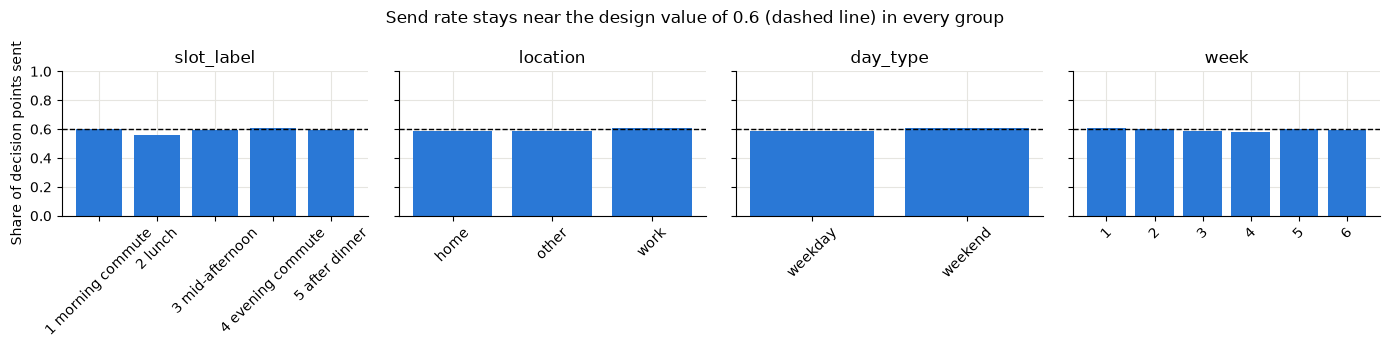

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.5), sharey=True)
for ax, col in zip(axes, ["slot_label", "location", "day_type", "week"]):
    rate = effect.groupby(col)["sent"].mean()
    ax.bar(rate.index.astype(str), rate.values, color=BLUE)
    ax.axhline(0.6, color="black", linestyle="--", linewidth=1)
    ax.set(title=col, ylim=(0, 1))
    ax.tick_params(axis="x", rotation=45)
axes[0].set_ylabel("Share of decision points sent")
fig.suptitle("Send rate stays near the design value of 0.6 (dashed line) in every group")
plt.tight_layout()
plt.show()

### 1-2. Steps before the decision
- Steps in the 30 minutes before the decision cannot be affected by the notification. 
- If they look alike in both groups, the groups were in a similar state right before the decision.

In [7]:
effect.groupby("sent")[["steps_pre30", "log_steps_pre30"]].agg(["mean", "median"]).round(2)

steps_pre30        log_steps_pre30       
            mean median            mean median
sent                                          
0         232.97   71.5            3.15   4.28
1         226.26   70.0            3.10   4.26

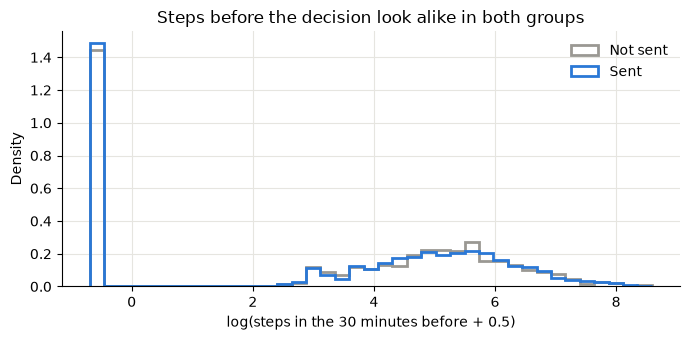

In [8]:
fig, ax = plt.subplots(figsize=(7, 3.5))
bins = np.linspace(effect["log_steps_pre30"].min(), effect["log_steps_pre30"].max(), 40)
for sent, color, label in [(0, GREY, "Not sent"), (1, BLUE, "Sent")]:
    values = effect.loc[effect["sent"] == sent, "log_steps_pre30"].dropna()
    ax.hist(values, bins=bins, density=True, histtype="step", linewidth=2, color=color, label=label)
ax.set(title="Steps before the decision look alike in both groups",
       xlabel="log(steps in the 30 minutes before + 0.5)", ylabel="Density")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

### Summary of section 1
- The send rate is 0.56-0.61 in every slot, location, day type, and week, close to the design value of 0.6.
- Mean (233 vs 226) and median (71.5 vs 70) steps before the decision are almost the same in both groups, and the distributions overlap.
- -> Randomization worked, so differences in steps between sent and not-sent decision points can be read as effects of the notification.

---

## 2. Steps after: sent vs not sent
The outcome is the log of steps in the 30 minutes after (`log_steps_post30`). The difference in log means, turned into a percentage, reads as "how many percent more steps when a notification is sent": `effect_pct = (exp(difference in log means) - 1) x 100`.

This section only compares group averages. Repeated observations of the same person and statistical uncertainty are handled with models in 03 and 04.

### 2-1. Overall

In [9]:
effect.groupby("sent")[["steps_post30", "log_steps_post30"]].agg(["mean", "median"]).round(2)

steps_post30        log_steps_post30       
             mean median             mean median
sent                                            
0          235.28   68.0             3.17   4.23
1          248.33   78.0             3.31   4.36

In [ ]:
log_means = effect.groupby("sent")["log_steps_post30"].mean() # 알림을 보낸 그룹(1)과 안 보낸 그룹(0)으로 나눠서, 알림 후 걸음 수의 로그 값 평균 구하기
overall_pct = (np.exp(log_means[1] - log_means[0]) - 1) * 100
print(f"Steps after a notification: {overall_pct:+.1f}% compared with no notification")

Steps after a notification: +14.9% compared with no notification


### 2-2. By situation
- Within each situation, compare sent with not sent. Columns `0` and `1` are the log means for not sent and sent.
- `n_not_sent` and `n_sent` are the counts for not sent and sent. If the smaller of the two is small, the difference can swing a lot.

In [12]:
# "알림을 보내면 걸음 수가 몇 % 늘어나는가"를 시간대, 장소, 평일·주말, 날씨마다 따로 구함

effect_tables = {}
for col in ["slot_label", "location", "day_type", "weather_group"]:
    table = effect.pivot_table(index=col, columns="sent", values="log_steps_post30", aggfunc="mean")
    table["effect_pct"] = (np.exp(table[1] - table[0]) - 1) * 100
    table["n_not_sent"] = (effect[effect["sent"] == 0].groupby(col).size())
    table["n_sent"] = (effect[effect["sent"] == 1].groupby(col).size())
    effect_tables[col] = table
    display(table.round(2))

sent,0,1,effect_pct,n_not_sent,n_sent
slot_label,,,,,
1 morning commute,2.02,2.04,2.69,481,730
2 lunch,3.50,3.80,35.50,496,634
3 mid-afternoon,3.30,3.56,29.67,475,703
4 evening commute,3.76,3.83,7.36,414,646
5 after dinner,3.38,3.47,10.34,475,692


sent,0,1,effect_pct,n_not_sent,n_sent
location,,,,,
home,3.17,3.36,21.54,639,916
other,3.19,3.26,7.74,1311,1878
work,3.15,3.43,32.87,364,568


sent,0,1,effect_pct,n_not_sent,n_sent
day_type,,,,,
weekday,3.13,3.43,33.81,1696,2412
weekend,3.28,3.04,-21.32,645,993


sent,0,1,effect_pct,n_not_sent,n_sent
weather_group,,,,,
clear,3.14,3.36,25.13,737,1151
cloudy,3.17,3.32,15.74,1453,2042
precipitation,3.32,2.93,-32.23,102,159


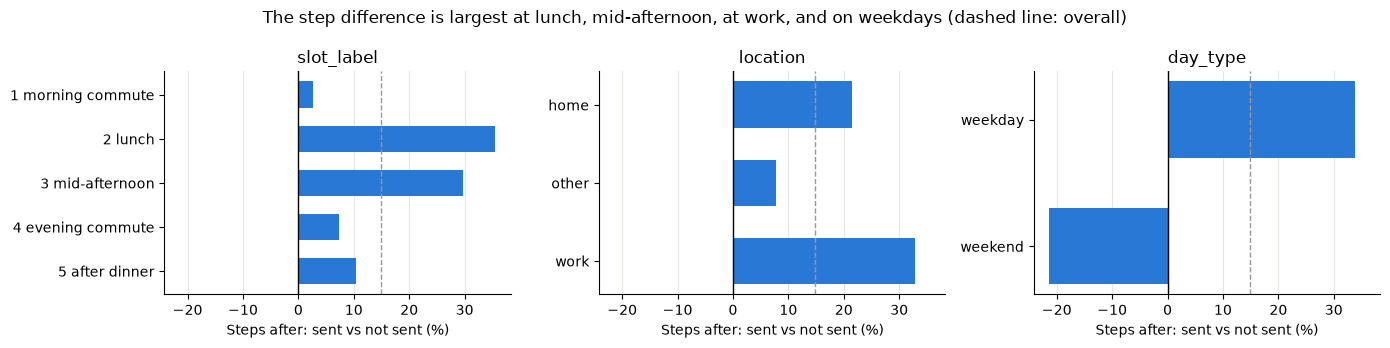

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5), sharex=True)
for ax, col in zip(axes, ["slot_label", "location", "day_type"]):
    pct = effect_tables[col]["effect_pct"].sort_index(ascending=False)
    ax.barh(pct.index.astype(str), pct.values, color=BLUE, height=0.6)
    ax.axvline(0, color="black", linewidth=1)
    ax.axvline(overall_pct, color=GREY, linestyle="--", linewidth=1)
    ax.set(title=col, xlabel="Steps after: sent vs not sent (%)")
    ax.grid(axis="y", visible=False)
fig.suptitle("The step difference is largest at lunch, mid-afternoon, at work, and on weekdays (dashed line: overall)")
plt.tight_layout()
plt.show()

### 2-3. By week in the study

In [14]:
weekly = effect.pivot_table(index="week", columns="sent", values="log_steps_post30", aggfunc="mean")
weekly["effect_pct"] = (np.exp(weekly[1] - weekly[0]) - 1) * 100
weekly["n_not_sent"] = effect[effect["sent"] == 0].groupby("week").size()
weekly["n_sent"] = effect[effect["sent"] == 1].groupby("week").size()
weekly.round(2)

sent,0,1,effect_pct,n_not_sent,n_sent
week,,,,,
1,3.08,3.70,86.49,358,550
2,3.12,3.31,21.43,392,582
3,3.18,3.29,11.61,369,518
4,3.16,3.13,-2.56,343,470
5,3.37,3.08,-24.74,361,537
6,3.15,3.32,18.20,518,748


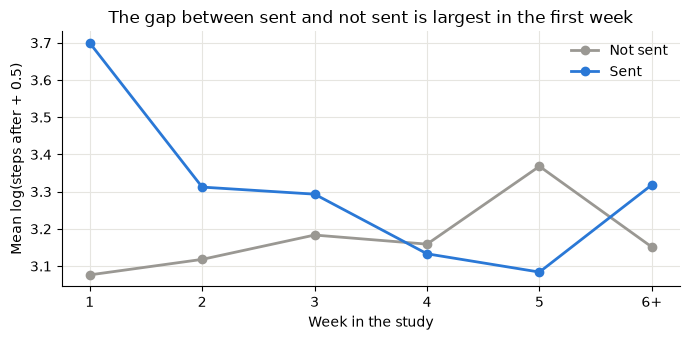

In [15]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(weekly.index, weekly[0], marker="o", color=GREY, linewidth=2, label="Not sent")
ax.plot(weekly.index, weekly[1], marker="o", color=BLUE, linewidth=2, label="Sent")
ax.set_xticks(weekly.index)
ax.set_xticklabels([f"{w}" if w < 6 else "6+" for w in weekly.index])
ax.set(title="The gap between sent and not sent is largest in the first week",
       xlabel="Week in the study", ylabel="Mean log(steps after + 0.5)")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

### Summary of section 2
- Overall, steps after a notification are about 15% higher.
- The difference is large at lunch (+36%), mid-afternoon (+30%), at work (+33%), and on weekdays (+34%), and small or reversed in the morning commute (+3%), evening commute (+7%), and on weekends (-21%).
- It is largest in the first week (+86%) and shrinks afterwards; from week 4 on it goes up and down from week to week.
- Small groups such as precipitation (n = 261) can swing a lot. → 04 checks these again with confidence intervals.

---

## 3. Engagement
- Look at whether users responded to a notification (`engaged` = 1: good, bad, or snoozed; 0: no response).

### 3-1. Overall and per-user engagement

In [16]:
print(f"Engagement rate: {engage['engaged'].mean():.3f}")

user_rate = engage.groupby("user_id")["engaged"].mean()
print(user_rate.describe().round(2))

Engagement rate: 0.685
count    37.00
mean      0.67
std       0.19
min       0.25
25%       0.53
50%       0.69
75%       0.85
max       0.93
Name: engaged, dtype: float64


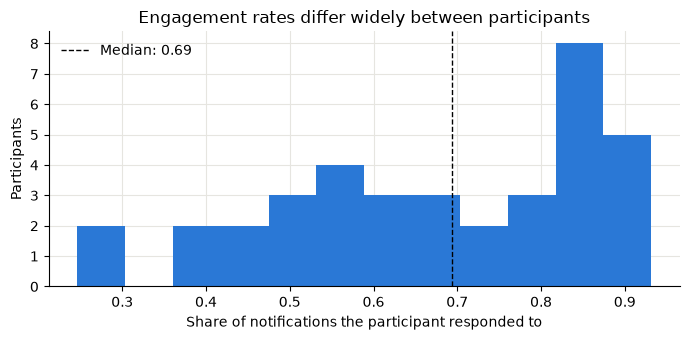

In [ ]:
# 알람에 얼마나 많이 반응 했는지
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(user_rate, bins=12, color=BLUE)
ax.axvline(user_rate.median(), color="black", linestyle="--", linewidth=1, label=f"Median: {user_rate.median():.2f}")
ax.set(title="Engagement rates differ widely between participants",
       xlabel="Share of notifications the participant responded to", ylabel="Participants")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

### 3-2. Engagement by situation
The `unknown` value of `send_type` (1 notification) has no recorded type and is ignored.

In [18]:
for col in ["slot_label", "location", "day_type", "week", "send_type"]:
    print(engage.groupby(col)["engaged"].agg(engagement_rate="mean", n="size").round(3))
    print()

                   engagement_rate    n
slot_label                             
1 morning commute            0.566  640
2 lunch                      0.696  546
3 mid-afternoon              0.758  598
4 evening commute            0.716  553
5 after dinner               0.703  572

          engagement_rate     n
location                       
home                0.644   787
other               0.673  1604
work                0.786   487

          engagement_rate     n
day_type                       
weekday             0.701  2053
weekend             0.647   856

      engagement_rate    n
week                      
1               0.724  445
2               0.678  478
3               0.685  448
4               0.645  414
5               0.722  472
6               0.663  652

           engagement_rate     n
send_type                       
active               0.689  1616
sedentary            0.681  1292
unknown              0.000     1



### 3-3. Engagement compared with the step difference
Put the engagement rate (3-2) next to the step difference (2-2) for each time slot.

In [19]:
compare = pd.DataFrame({
    "engagement_rate": engage.groupby("slot_label")["engaged"].mean(),
    "step_effect_pct": effect_tables["slot_label"]["effect_pct"],
})
compare.round(3)

,engagement_rate,step_effect_pct
slot_label,,
1 morning commute,0.566,2.689
2 lunch,0.696,35.499
3 mid-afternoon,0.758,29.670
4 evening commute,0.716,7.360
5 after dinner,0.703,10.339


### Summary of section 3
- The overall engagement rate is 68.5%, ranging from 25% to 93% across participants.
- Engagement is lowest in the morning commute (57%) and high mid-afternoon (76%) and at work (79%).
- **High engagement does not mean more steps.** The evening commute has a high engagement rate (72%) but only a +7% step difference, while lunch has 70% engagement and the largest step difference (+36%).
- -> Notification policy cannot rely on engagement alone; the step effect (04) must be considered too.

---

## 4. Missing values
- The effect analysis leaves out decision points with no outcome. 
- If missing values were related to sending, leaving them out could bias the result. 
- Compare the share of missing outcomes in the shared sample (`base`).

In [20]:
base["outcome_missing"] = base["steps_post30"].isna()

for col in ["sent", "slot_label", "week"]:
    print(base.groupby(col)["outcome_missing"].agg(missing_rate="mean", n="size").round(3))
    print()

      missing_rate     n
sent                    
0            0.091  2576
1            0.093  3755

                   missing_rate     n
slot_label                           
1 morning commute         0.113  1366
2 lunch                   0.095  1249
3 mid-afternoon           0.079  1279
4 evening commute         0.096  1173
5 after dinner            0.077  1264

      missing_rate     n
week                    
1            0.044   950
2            0.048  1023
3            0.077   961
4            0.131   936
5            0.100   998
6            0.135  1463



- The response is also missing for some sent notifications (section 5.5 of notebook 01). Look at the share by week.

In [22]:
sent_base = base[base["sent"] == 1]
print(f"Response not recorded among sent notifications: {sent_base['engaged'].isna().mean():.3f}")
sent_base.groupby("week")["engaged"].apply(lambda x: x.isna().mean()).round(3).rename("response_missing_rate")

Response not recorded among sent notifications: 0.225


week
1    0.223
2    0.223
3    0.204
4    0.235
5    0.211
6    0.246
Name: response_missing_rate, dtype: float64

### Summary of section 4
- The missing-outcome rate is almost the same for sent (9.3%) and not sent (9.1%). -> Missingness is unrelated to sending, so leaving it out is acceptable for the effect comparison.
- Missing outcomes increase later in the study (4.4% in week 1 to 13.5% in week 6 and later), suggesting participants wore the tracker less. -> 03 repeats the analysis with missing values set to 0 to check that conclusions hold.
- 22.5% of sent notifications have no recorded response, at a similar share in every week.

---

## 5. Summary

| 질문 / Question | 답 / Answer | 다음 단계 / Next |
| --- | --- | --- |
| Did randomization work? | Yes: send rate 0.56-0.61, pre-decision steps nearly equal | 03 compares sent with not sent |
| Do steps increase? | About +15% overall, largest in week 1 | 03 models the average effect and its decline |
| Does it depend on the situation? | Large at lunch, mid-afternoon, at work, on weekdays | 04 tests this with confidence intervals |
| Engagement = effect? | No: evening commute has high engagement but a small effect | 05 analyzes engagement |
| Can missing outcomes be left out? | Yes, unrelated to sending, but rises later | 03 runs a sensitivity check with missing set to 0 |